In [1]:
import duckdb
from pathlib import Path

reviews_path = Path.cwd() / "Video_Games.jsonl.gz"

print("Looking for dataset at:", reviews_path)

if not reviews_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Make sure the notebook is in the CommerceIQ_Data folder."
    )

con = duckdb.connect()
con.execute("PRAGMA disable_progress_bar")
path_for_sql = reviews_path.as_posix().replace("'", "''")

result = con.execute(f"""
    SELECT
        COUNT(*) AS total_reviews,
        COUNT(DISTINCT parent_asin) AS distinct_products,
        SUM(CASE
            WHEN parent_asin IS NULL OR TRIM(parent_asin) = ''
            THEN 1 ELSE 0
        END) AS reviews_missing_product_id
    FROM read_json_auto(
        '{path_for_sql}',
        format = 'newline_delimited'
    )
""").df()

result

Looking for dataset at: c:\Users\Saakshi\OneDrive\Documents\CommerceIQ_Data\Video_Games.jsonl.gz


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_reviews,distinct_products,reviews_missing_product_id
0,4624615,137249,0.0


In [2]:
con.execute(f"""
    DESCRIBE SELECT * FROM read_json_auto('{path_for_sql}', format='newline_delimited')
""").df()

,column_name,column_type,null,key,default,extra
0,rating,DOUBLE,YES,None,None,None
1,title,VARCHAR,YES,None,None,None
2,text,VARCHAR,YES,None,None,None
3,images,"STRUCT(small_image_url VARCHAR, medium_image_u...",YES,None,None,None
4,asin,VARCHAR,YES,None,None,None
5,parent_asin,VARCHAR,YES,None,None,None
6,user_id,VARCHAR,YES,None,None,None
7,timestamp,BIGINT,YES,None,None,None
8,helpful_vote,BIGINT,YES,None,None,None
9,verified_purchase,BOOLEAN,YES,None,None,None


In [3]:
con.execute(f"""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) - COUNT(DISTINCT (user_id, parent_asin, timestamp, text)) AS duplicate_rows
    FROM read_json_auto('{path_for_sql}', format='newline_delimited')
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,duplicate_rows
0,4624615,53653


In [4]:
con.execute(f"""
    COPY (
        SELECT DISTINCT parent_asin, user_id, rating, text,
               to_timestamp(timestamp / 1000) AS ts,
               verified_purchase
        FROM read_json_auto('{path_for_sql}', format='newline_delimited')
        WHERE parent_asin IS NOT NULL AND timestamp IS NOT NULL AND rating IS NOT NULL
    ) TO 'reviews_clean.parquet' (FORMAT parquet)
""")
con.execute("SELECT COUNT(*) AS reviews, COUNT(DISTINCT parent_asin) AS products FROM 'reviews_clean.parquet'").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,reviews,products
0,4570962,137249


In [5]:
con.execute("""
CREATE OR REPLACE TABLE labels AS
WITH r AS (
    SELECT parent_asin, ts FROM 'reviews_clean.parquet'
),
f AS (                                   -- each product's first review time
    SELECT parent_asin, MIN(ts) AS t0 FROM r GROUP BY parent_asin
),
d AS (                                   -- days since that first review, for every review
    SELECT r.parent_asin, f.t0, (epoch(r.ts) - epoch(f.t0)) / 86400.0 AS day
    FROM r JOIN f USING (parent_asin)
),
c AS (                                   -- count reviews in each time window
    SELECT parent_asin, t0,
           COUNT(*) FILTER (WHERE day < 30)                AS n_first30,
           COUNT(*) FILTER (WHERE day >= 30 AND day < 120) AS n_outcome
    FROM d GROUP BY parent_asin, t0
)
SELECT *, CASE WHEN n_outcome >= 37 THEN 1 ELSE 0 END AS high_engagement
FROM c
WHERE n_first30 >= 3
  AND t0 + INTERVAL 120 DAY <= (SELECT MAX(ts) FROM r)
""")

con.execute("""
    SELECT high_engagement, COUNT(*) AS products,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM labels GROUP BY high_engagement ORDER BY high_engagement
""").df()

,high_engagement,products,pct
0,0,21266,89.9
1,1,2400,10.1


In [6]:
import pandas as pd

df = con.execute("SELECT * FROM labels").df()
df = df.sort_values("t0").reset_index(drop=True)      # oldest products first

n = len(df)
i_val, i_test = int(n * 0.6), int(n * 0.8)

df["split"] = "train"
df.loc[i_val:i_test - 1, "split"] = "val"
df.loc[i_test:, "split"] = "test"

# the top-10% cutoff comes from TRAIN products only
cutoff = df.loc[df["split"] == "train", "n_outcome"].quantile(0.90)
print("Cutoff from train only:", cutoff)
df["high_engagement"] = (df["n_outcome"] >= cutoff).astype(int)

df.groupby("split").agg(
    products=("parent_asin", "count"),
    first_start=("t0", "min"),
    last_start=("t0", "max"),
    pct_high=("high_engagement", lambda s: round(100 * s.mean(), 1)),
)

Cutoff from train only: 48.0


,products,first_start,last_start,pct_high
split,,,,
test,4734,2021-06-09 05:52:36.367+05:30,2023-05-15 03:30:30.111+05:30,3.3
train,14199,1999-10-30 01:10:04.000+05:30,2019-12-06 20:09:00.106+05:30,10.1
val,4733,2019-12-06 20:15:22.619+05:30,2021-06-09 04:01:18.009+05:30,3.8


In [7]:
con.register("split_df", df[["parent_asin", "t0", "split", "high_engagement"]])

for W in (7, 14, 30):
    con.execute(f"""
    CREATE OR REPLACE TABLE feat_{W} AS
    SELECT s.parent_asin, s.split, s.high_engagement,
           COUNT(*)                                          AS n_reviews,
           COUNT(*) / {W}.0                                  AS arrival_rate,
           AVG(r.rating)                                     AS rating_mean,
           COALESCE(STDDEV_SAMP(r.rating), 0)                AS rating_std,
           AVG(CASE WHEN r.rating = 5  THEN 1.0 ELSE 0 END)  AS pct_5star,
           AVG(CASE WHEN r.rating <= 2 THEN 1.0 ELSE 0 END)  AS pct_low,
           AVG(CASE WHEN r.verified_purchase THEN 1.0 ELSE 0 END) AS pct_verified,
           AVG(LENGTH(r.text))                               AS avg_review_len
    FROM split_df s
    JOIN 'reviews_clean.parquet' r USING (parent_asin)
    WHERE (epoch(r.ts) - epoch(s.t0)) / 86400.0 < {W}
    GROUP BY s.parent_asin, s.split, s.high_engagement
    HAVING COUNT(*) >= 3
    """)

out = []
for W in (7, 14, 30):
    t = con.execute(f"""
        SELECT {W} AS window_days, split, COUNT(*) AS products,
               ROUND(100 * AVG(high_engagement), 1) AS pct_high
        FROM feat_{W} GROUP BY split ORDER BY split
    """).df()
    out.append(t)
pd.concat(out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,window_days,split,products,pct_high
0,7,test,1705,7.0
1,7,train,5928,19.5
2,7,val,1448,8.6
0,14,test,2888,5.1
1,14,train,8928,14.8
2,14,val,2719,5.9
0,30,test,4734,3.3
1,30,train,14199,10.1
2,30,val,4733,3.8


In [8]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score

FEATS = ["n_reviews", "arrival_rate", "rating_mean", "rating_std",
         "pct_5star", "pct_low", "pct_verified", "avg_review_len"]
K = 50   # "promote the top 50 products"

def precision_at_k(y, score, k):
    top = np.argsort(-score)[:k]
    return y[top].mean()

rows = []
for W in (7, 14, 30):
    d = con.execute(f"SELECT * FROM feat_{W}").df()
    train = d[d.split == "train"]

    models = {
        "logistic regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
        "gradient boosting": HistGradientBoostingClassifier(random_state=0),
    }
    for m in models.values():
        m.fit(train[FEATS], train["high_engagement"])

    for sp in ("val", "test"):
        ev = d[d.split == sp]
        y = ev["high_engagement"].values
        scores = {"baseline (review count)": ev["n_reviews"].values}
        for name, m in models.items():
            scores[name] = m.predict_proba(ev[FEATS])[:, 1]

        for name, s in scores.items():
            rows.append({
                "window": W, "split": sp, "model": name,
                "PR-AUC": round(average_precision_score(y, s), 3),
                f"precision@{K}": round(precision_at_k(y, s, K), 2),
                "base_rate": round(y.mean(), 3),
            })

results = pd.DataFrame(rows)
results[results.split == "test"]


,window,split,model,PR-AUC,precision@50,base_rate
3,7,test,baseline (review count),0.454,0.76,0.070
4,7,test,logistic regression,0.454,0.74,0.070
5,7,test,gradient boosting,0.450,0.74,0.070
9,14,test,baseline (review count),0.428,0.80,0.051
10,14,test,logistic regression,0.446,0.82,0.051
11,14,test,gradient boosting,0.432,0.74,0.051
15,30,test,baseline (review count),0.532,0.86,0.033
16,30,test,logistic regression,0.543,0.82,0.033
17,30,test,gradient boosting,0.530,0.80,0.033


In [9]:
rng = np.random.default_rng(0)

def boot_ci(y, s_model, s_base, n=1000):
    diffs, aucs = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0:
            continue
        a = average_precision_score(y[i], s_model[i])
        b = average_precision_score(y[i], s_base[i])
        aucs.append(a)
        diffs.append(a - b)
    return np.percentile(aucs, [2.5, 97.5]), np.percentile(diffs, [2.5, 97.5])

rows = []
for W in (7, 14, 30):
    d = con.execute(f"SELECT * FROM feat_{W}").df()
    train, test = d[d.split == "train"], d[d.split == "test"]
    y = test["high_engagement"].values
    base = test["n_reviews"].values

    models = {
        "logistic regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
        "gradient boosting": HistGradientBoostingClassifier(random_state=0),
    }
    for name, m in models.items():
        m.fit(train[FEATS], train["high_engagement"])
        s = m.predict_proba(test[FEATS])[:, 1]
        auc_ci, diff_ci = boot_ci(y, s, base)
        rows.append({
            "window": W, "model": name,
            "PR-AUC": round(average_precision_score(y, s), 3),
            "PR-AUC 95% CI": f"{auc_ci[0]:.3f} to {auc_ci[1]:.3f}",
            "gain vs baseline 95% CI": f"{diff_ci[0]:+.3f} to {diff_ci[1]:+.3f}",
        })

pd.DataFrame(rows[-6:])

,window,model,PR-AUC,PR-AUC 95% CI,gain vs baseline 95% CI
0,7,logistic regression,0.454,0.365 to 0.550,-0.022 to +0.024
1,7,gradient boosting,0.450,0.359 to 0.546,-0.047 to +0.040
2,14,logistic regression,0.446,0.368 to 0.525,+0.004 to +0.032
3,14,gradient boosting,0.432,0.351 to 0.517,-0.027 to +0.038
4,30,logistic regression,0.543,0.462 to 0.617,+0.001 to +0.022
5,30,gradient boosting,0.530,0.451 to 0.606,-0.028 to +0.025


In [10]:
rng = np.random.default_rng(0)

def boot_ci(y, s_model, s_base, n=1000):
    diffs, aucs = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0:
            continue
        a = average_precision_score(y[i], s_model[i])
        b = average_precision_score(y[i], s_base[i])
        aucs.append(a)
        diffs.append(a - b)
    return np.percentile(aucs, [2.5, 97.5]), np.percentile(diffs, [2.5, 97.5])

rows = []
for W in (7, 14, 30):
    d = con.execute(f"SELECT * FROM feat_{W}").df()
    train, test = d[d.split == "train"], d[d.split == "test"]
    y = test["high_engagement"].values
    base = test["n_reviews"].values

    models = {
        "logistic regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
        "gradient boosting": HistGradientBoostingClassifier(random_state=0),
    }
    for name, m in models.items():
        m.fit(train[FEATS], train["high_engagement"])
        s = m.predict_proba(test[FEATS])[:, 1]
        auc_ci, diff_ci = boot_ci(y, s, base)
        rows.append({
            "window": W, "model": name,
            "PR-AUC": round(average_precision_score(y, s), 3),
            "PR-AUC 95% CI": f"{auc_ci[0]:.3f} to {auc_ci[1]:.3f}",
            "gain vs baseline 95% CI": f"{diff_ci[0]:+.3f} to {diff_ci[1]:+.3f}",
        })

pd.DataFrame(rows[-6:])

,window,model,PR-AUC,PR-AUC 95% CI,gain vs baseline 95% CI
0,7,logistic regression,0.454,0.365 to 0.550,-0.022 to +0.024
1,7,gradient boosting,0.450,0.359 to 0.546,-0.047 to +0.040
2,14,logistic regression,0.446,0.368 to 0.525,+0.004 to +0.032
3,14,gradient boosting,0.432,0.351 to 0.517,-0.027 to +0.038
4,30,logistic regression,0.543,0.462 to 0.617,+0.001 to +0.022
5,30,gradient boosting,0.530,0.451 to 0.606,-0.028 to +0.025


Matplotlib is building the font cache; this may take a moment.
Background dataset has 14199 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=14199 when initializing the masker.


Test PR-AUC without arrival_rate: 0.543


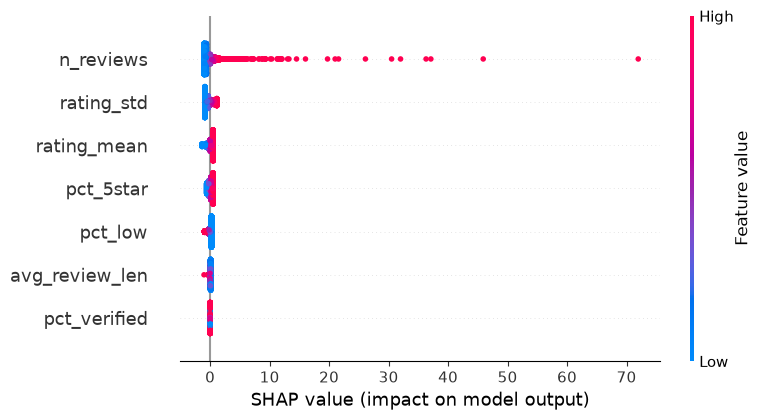

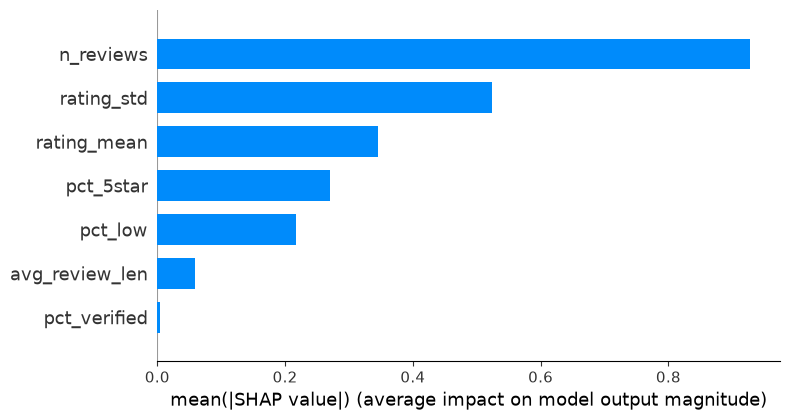

In [11]:
import shap
import matplotlib.pyplot as plt

FEATS2 = [f for f in FEATS if f != "arrival_rate"]

d = con.execute("SELECT * FROM feat_30").df()
train, test = d[d.split == "train"], d[d.split == "test"]

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
pipe.fit(train[FEATS2], train["high_engagement"])

# Check: the score should be about the same as before (about 0.543)
print("Test PR-AUC without arrival_rate:",
      round(average_precision_score(test["high_engagement"],
                                    pipe.predict_proba(test[FEATS2])[:, 1]), 3))

scaler, clf = pipe[0], pipe[1]
X_tr = scaler.transform(train[FEATS2])
X_te = scaler.transform(test[FEATS2])

explainer = shap.LinearExplainer(clf, X_tr)
sv = explainer.shap_values(X_te)

shap.summary_plot(sv, X_te, feature_names=FEATS2)                       # direction and size of each feature's effect
shap.summary_plot(sv, X_te, feature_names=FEATS2, plot_type="bar")      # overall importance ranking

In [12]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

txt = con.execute("""
    SELECT s.parent_asin, r.text
    FROM split_df s
    JOIN 'reviews_clean.parquet' r USING (parent_asin)
    WHERE (epoch(r.ts) - epoch(s.t0)) / 86400.0 < 30
      AND s.parent_asin IN (SELECT parent_asin FROM feat_30)
""").df()
print("Reviews to score:", len(txt))

sia = SentimentIntensityAnalyzer()
txt["sent"] = txt["text"].fillna("").map(lambda t: sia.polarity_scores(t)["compound"])

sent = txt.groupby("parent_asin")["sent"].agg(
    sent_mean="mean", sent_min="min",
    pct_neg_text=lambda s: (s < -0.05).mean()).reset_index()

d = con.execute("SELECT * FROM feat_30").df().merge(sent, on="parent_asin", how="left")
train, test = d[d.split == "train"], d[d.split == "test"]
y = test["high_engagement"].values

TEXT_FEATS = ["sent_mean", "sent_min", "pct_neg_text"]

def fit_score(cols):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
    m.fit(train[cols], train["high_engagement"])
    return m.predict_proba(test[cols])[:, 1]

s_ratings = fit_score(FEATS2)
s_with_text = fit_score(FEATS2 + TEXT_FEATS)

auc_ci, diff_ci = boot_ci(y, s_with_text, s_ratings)
print("Ratings only   PR-AUC:", round(average_precision_score(y, s_ratings), 3))
print("Ratings + text PR-AUC:", round(average_precision_score(y, s_with_text), 3))
print(f"Gain from text, 95% CI: {diff_ci[0]:+.3f} to {diff_ci[1]:+.3f}")

ModuleNotFoundError: No module named 'vaderSentiment'

In [13]:
%pip install vaderSentiment

  Using cached vaderSentiment-3.3.2-py2.py3-none-any.whl.metadata (572 bytes)
Using cached vaderSentiment-3.3.2-py2.py3-none-any.whl (125 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

txt = con.execute("""
    SELECT s.parent_asin, r.text
    FROM split_df s
    JOIN 'reviews_clean.parquet' r USING (parent_asin)
    WHERE (epoch(r.ts) - epoch(s.t0)) / 86400.0 < 30
      AND s.parent_asin IN (SELECT parent_asin FROM feat_30)
""").df()
print("Reviews to score:", len(txt))

sia = SentimentIntensityAnalyzer()
txt["sent"] = txt["text"].fillna("").map(lambda t: sia.polarity_scores(t)["compound"])

sent = txt.groupby("parent_asin")["sent"].agg(
    sent_mean="mean", sent_min="min",
    pct_neg_text=lambda s: (s < -0.05).mean()).reset_index()

d = con.execute("SELECT * FROM feat_30").df().merge(sent, on="parent_asin", how="left")
train, test = d[d.split == "train"], d[d.split == "test"]
y = test["high_engagement"].values

TEXT_FEATS = ["sent_mean", "sent_min", "pct_neg_text"]

def fit_score(cols):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
    m.fit(train[cols], train["high_engagement"])
    return m.predict_proba(test[cols])[:, 1]

s_ratings = fit_score(FEATS2)
s_with_text = fit_score(FEATS2 + TEXT_FEATS)

auc_ci, diff_ci = boot_ci(y, s_with_text, s_ratings)
print("Ratings only   PR-AUC:", round(average_precision_score(y, s_ratings), 3))
print("Ratings + text PR-AUC:", round(average_precision_score(y, s_with_text), 3))
print(f"Gain from text, 95% CI: {diff_ci[0]:+.3f} to {diff_ci[1]:+.3f}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Reviews to score: 295024
Ratings only   PR-AUC: 0.543
Ratings + text PR-AUC: 0.534
Gain from text, 95% CI: -0.019 to +0.000
